# QLoRA Lab: Fine-tuning Qwen2.5-1.5B on DialogSum

## Install packages

In [ ]:
%pip install -q -U bitsandbytes rouge_score
%pip uninstall -y -q torchao

## Setup

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
import math, random, time
from pathlib import Path
import torch, transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN, N_EVAL, MAX_LEN = 2000, 60, 512
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none")

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.2.2+cu118 | transformers 4.57.1
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## Exercise 1 — Memory budget

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8

def memory_budget(n_total, n_linear, n_other, n_lora):
    return {"full FT": 16 * n_total / GB,
            "LoRA": (2 * n_total + 16 * n_lora) / GB,
            "QLoRA": (NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora) / GB}

estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4: False
LoRA       3.38 GB   fits on a 16 GB T4: True
QLoRA      1.91 GB   fits on a 16 GB T4: True
Exercise 1 checks passed.


## Answer — Question 1

(a) LoRA (3.38 GB) and QLoRA (1.91 GB) fit on a 16 GB T4; full fine-tuning (24.70 GB) does not. (b) Reason to practise: the same recipe scales to 7B+ models where 16-bit LoRA no longer fits, so we learn it on a small, cheap model. Cost: 4-bit quantization adds dequantization overhead (slower steps) and a small quality loss vs. a 16-bit base. (c) About 5 × 1.91 ≈ 9.5 GB before activations.

## Load data and tokenizer

In [4]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
example = raw["train"][0]
print(example["dialogue"][:600], "\n\nSUMMARY:", example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1 

SUMMARY: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.


## Prompt template

In [5]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"

def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



## Exercise 2 — Training examples with masked prompt

In [6]:
def build_example(dialogue, summary):
    p = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    a = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    return {"input_ids": p + a, "attention_mask": [1] * (len(p) + len(a)), "labels": [-100] * len(p) + a}

ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt])
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:]
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END)
print("scored text:", tokenizer.decode([t for t in ex["labels"] if t != -100]))
print("Exercise 2 checks passed.")

scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


## Build train and eval sets

In [7]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"kept {len(train_data)}, dropped {N_TRAIN - len(train_data)} | median len {sorted(lengths)[len(lengths)//2]}, max {max(lengths)}")
print(f"scored tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,}")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

kept 1940, dropped 60 | median len 265, max 1231
scored tokens: 65,739 of 536,797


## Answer — Question 2

(a) Without masking, the model would also learn to reproduce the system message, instruction and dialogue. Only 65,739 of 536,797 tokens (~12%) are summary tokens, so ~88% of the loss would be spent on copying the prompt instead of learning to summarize. (b) `<|im_end|>` teaches the model when to stop; without it, it would keep generating (extra text, new turns) until `max_new_tokens`. (c) Truncation cuts off the end of the example, i.e. the summary, which is the only part being learned; dropping removed just 60 of 2,000 examples.

## Exercise 3 — Load model in 4-bit

In [8]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
import bitsandbytes as bnb

bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(CKPT, quantization_config=bnb_config,
                                             dtype=torch.float16, device_map={"": 0})

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory: {loaded_gb:.2f} GB")
assert n4 == 28 * 7 and loaded_gb < 2.0
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory: 1.15 GB
Exercise 3 checks passed.


## Answer — Question 3

Measured 1.15 GB, almost exactly the ~1.14 GB estimate. Small differences come from the 16-bit embedding/LM head, quantization scales, CUDA context and allocator overhead. T4 has no bfloat16 support, so `float16` is the fast compute dtype there; on an A100 we would use `torch.bfloat16` (same speed, wider range, no overflow).

## Exercise 4 — Baseline generation

In [9]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]

start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:5]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

D:\bennett\gen ai\module 3\lab3\.venv\lib\site-packages\transformers\integrations\sdpa_attention.py:96: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


generated 60 summaries in 51 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also intro

## Exercise 4 — ROUGE

In [10]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def rouge(preds, refs):
    s = [scorer.score(r, p) for p, r in zip(preds, refs)]
    return {k: 100 * sum(x[k].fmeasure for x in s) / len(s) for k in ROUGE_KEYS}

assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 31.3, 'rouge2': 8.1, 'rougeL': 22.7} | mean words: model 33, reference 22
Exercise 4 checks passed.


## Answer — Question 4

(a) The base model writes longer summaries (33 vs. 22 words), uses generic openings like "The conversation is about…", "The speaker…", and often uses real names or vague references instead of `#Person1#/#Person2#`. It also adds extra detail (e.g. the school tour example). (b) Length, the "The conversation is about" phrasing and using names instead of `#PersonN#` lower ROUGE without making the summary worse for a reader. ROUGE baseline: R1 31.3, R2 8.1, RL 22.7.

## Exercise 5 — Attach LoRA

In [11]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
lora_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(OUT / "trainer"), per_device_train_batch_size=4, gradient_accumulation_steps=4,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10,
    fp16=True, optim="paged_adamw_8bit", gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False}, logging_steps=10,
    save_strategy="no", report_to="none", remove_unused_columns=False, seed=SEED)

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,}")
assert n_trainable == N_LORA and args.fp16 and not args.bf16 and "paged" in str(args.optim).lower()
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768
Exercise 5 configuration checks passed.


## Exercise 5 — Train

In [12]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}

trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB (estimate {estimate['QLoRA']:.2f} GB)")

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Step,Training Loss
10,1.297500
20,1.096000
30,1.074900
40,1.031700
50,0.982200
60,1.006900
70,1.043500
80,0.970800
90,0.933700
100,1.025400


training time: 28.7 min | peak GPU memory: 6.37 GB (estimate 1.91 GB)


## Training loss curve

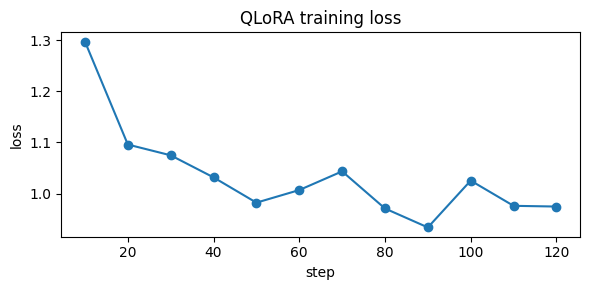

Exercise 5 checks passed.


In [13]:
import matplotlib.pyplot as plt

steps, losses = zip(*[(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h])
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses) and losses[-1] < losses[0]
print("Exercise 5 checks passed.")

## Answer — Question 5

(a) Training took 28.7 min with a peak of 6.37 GB (run on a 4 GB RTX 3050 laptop GPU, so part spilled to shared memory, which slowed it down; a T4 would be faster). The peak is above the 1.91 GB estimate because of activations, the 151k-vocab logits in fp32 for the loss, and CUDA workspace. Gradient checkpointing, the paged 8-bit optimizer, and a small per-device batch (4, with accumulation for 16) keep it from being much higher. (b) Training loss only shows the model fits the training summaries (style + tokens); it says nothing about unseen dialogues, factual correctness, or overfitting — we need held-out evaluation.

## Exercise 6 — Evaluate fine-tuned model

In [14]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(scorer.score(r, t)["rougeL"].fmeasure > scorer.score(r, b)["rougeL"].fmeasure
           for r, t, b in zip(eval_refs, tuned_preds, base_preds))

print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
print("Exercise 6 checks passed.")

generated 60 summaries in 62 s
               rouge1   rouge2   rougeL   words
base             31.3      8.1     22.7      33
QLoRA            46.0     18.9     37.3      21
reference                                    22

QLoRA ROUGE-L higher on 55 of 60 dialogues
Exercise 6 checks passed.


## Answer — Question 6

(a) ROUGE rose sharply: R1 31.3 → 46.0, R2 8.1 → 18.9, RL 22.7 → 37.3, and the tuned model wins on 55/60 dialogues. Length dropped from 33 to 21 words, matching the references (22). (b) Shorter outputs raise precision and F1 simply by matching reference length; using the `#Person1#` convention and DialogSum's phrasing ("#Person1# asks #Person2#…") adds word overlap without better content. (c) More evaluation examples (the full 500 validation or test set), confidence intervals / bootstrap, several training seeds, and a human evaluation of faithfulness.

## Exercise 7 — Blind samples

In [15]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200])
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

## Exercise 7 — Ratings and reveal

In [16]:
# (A_faithful, A_coverage, B_faithful, B_coverage) per example, in printed order -- edit after reading
scores = [(0, 1, 2, 2), (1, 1, 2, 1), (2, 1, 2, 2), (1, 0, 2, 2), (0, 1, 2, 2), (2, 1, 1, 1)]
ratings = {i: dict(zip(["A_faithful", "A_coverage", "B_faithful", "B_coverage"], s)) for i, s in zip(HUMAN_IDS, scores)}

totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for m, p in ((a_model, "A"), (b_model, "B")):
        totals[m][0] += r[f"{p}_faithful"]; totals[m][1] += r[f"{p}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
for m, (f, c) in totals.items():
    print(f"{m:<6} mean faithfulness {f / 6:.2f} | mean coverage {c / 6:.2f}  (out of 2)")

example 40: A = base, B = QLoRA
example 7: A = base, B = QLoRA
example 1: A = base, B = QLoRA
example 47: A = base, B = QLoRA
example 17: A = base, B = QLoRA
example 15: A = base, B = QLoRA
base   mean faithfulness 1.00 | mean coverage 0.83  (out of 2)
QLoRA  mean faithfulness 1.83 | mean coverage 1.67  (out of 2)


## Answer — Question 7

(a) Yes: humans also preferred QLoRA (faithfulness 1.83 vs 1.00, coverage 1.67 vs 0.83). A partial disagreement is example 7: the QLoRA summary overlaps the reference well but misses Wendy's main argument (jobs/income), while the base summary captures it but adds an invented detail. (b) Yes, the base model invented facts: in example 40 it said an "event occurred on May 20, 1963" (that was the birthday) and in example 17 it said "Adam is apologizing because he got off work late" (it was Alice). QLoRA had only a minor error (example 15, "she can't help"). (c) Only 6 examples and one rater (me), who might be biased → use many examples and multiple independent raters with agreement statistics. The A/B order was always base = A here, so blinding was weak → properly randomize and hide model identity.

## Exercise 8 — Save adapter

In [17]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB
README.md                            0.0 MB


## Answer — Question 8

(a) 18,464,768 trainable parameters × 4 bytes (fp32) ≈ 73.9 MB, which is exactly the saved file size — about 2% of the 3.1 GB base. (b) Load the base model in 16-bit (not 4-bit), load the adapter with `PeftModel.from_pretrained`, call `merge_and_unload()`, and `save_pretrained` the merged model and tokenizer. Afterwards re-check: summaries/ROUGE on the validation set match the adapter version, generation stops at `<|im_end|>`, and the chat template is saved.

## Reflection

I would recommend this model for a pilot, not for full deployment yet. After 29 minutes of QLoRA on 1,940 dialogues, ROUGE-L rose from 22.7 to 37.3, it beat the base model on 55 of 60 dialogues, its summaries match the team's length (21 vs 22 words) and speaker style, and in my blind ratings it was more faithful (1.83 vs 1.00) and covered more (1.67 vs 0.83); the base model invented facts, such as the wrong person apologizing. However, the evidence is limited: 60 validation examples, one training run, and six human-rated examples from a single rater. ROUGE rewards style and length, so part of the gain is format, and it does not prove the model never invents statements. DialogSum is also not real customer-service data and is non-commercial. Next, I would evaluate on the full test set with several seeds and multiple raters, and test on real (consented, anonymized) support conversations focusing on hallucinated statements.